# Graph Builder

Testing scripts to build a knowledge graph from entity specifications in YAML format. For Samuel Ostrove’s senior thesis in Computing and Linguistics.

In [1]:
import yaml
from abc import ABC, abstractmethod
from typing import Dict, Optional
import numpy as np
import scipy.stats as ss
import networkx as nx
import matplotlib.pyplot as plt

## Figuring out PyYAML

In [6]:
# YAML reading
## Read single-document YAML file
test_path_1 = "./testyaml1.yml"
with open(test_path_1, 'r') as spec:
    print(yaml.safe_load(spec))

## Read multi-document YAML file
test_path_2 = "./testyaml2.yml"
with open(test_path_2, 'r') as spec:
    docs = yaml.safe_load_all(spec)
    for doc in docs:
        print(doc)

{'test1': [{'type': 'string'}, {'name': 'group'}, {'specs': [{'share': 'good'}]}]}
{'name': 'doc1'}
{'name': 'doc2'}


In [7]:
# YAML dumping
triples = [["Will", "sibling_of", "Stellan"],
           ["Hannah", "child_of", "Zoltan"]]
testdict = {'sibling_of': {'recip': 'sibling_of'}}
dump_path = "./testdump1.yml"
with open(dump_path, 'w') as path:
    yaml.dump(testdict, path)

In [8]:
# Loading the graph into three lists
spec_path = "./testGraph1.yml"
with open(spec_path, 'r') as spec:
    docs = yaml.safe_load_all(spec)
    types, nodes, rels = docs

## Infrastructure

### Utility functions

In [2]:
## Set generation for person nodes
def randGen() -> int:
    return np.random.choice(np.arange(0, 3), size = 1, p = np.array([.2, .4, .4]))[0]

## Print the list of relations being checked
def printChecking(checking:list[tuple]):
    for i in checking:
        print(i[1].getProp('Name'), i[0].getName(), i[2].getProp('Name'))

### Relations

In [3]:
# Relation class

class relation:
    """
    Class for relations, for internal use only.
    """
    # Hyperparameters
    defaultmax = 10

    # Method definitions
    def __init__(self, name:str):
        self.name = name
        self.subj_class = None
        self.obj_class = None
        self.recip = list()
        self.share = list()
        self.onehop = list()
        self.no = list()
        self.max = int()
        self.gen = int()
    
    def specify(self, subj:ABC, obj:ABC, recip:list = [], 
                share:list = [], onehop:list = [], no:list = [], max:int = defaultmax, gen:int = None):
        self.subj_class = subj
        self.obj_class = obj
        self.recip = recip
        self.share = share
        self.onehop = onehop
        self.no = no
        self.max = max
        self.gen = gen
    
    def getName(self) -> str:
        return self.name
    
    def getClasses(self) -> tuple[ABC, ABC]:
        return self.subj_class, self.obj_class
    
    def getRecip(self) -> list:
        return self.recip
    
    def getNots(self) -> list:
        return self.no
    
    def getShare(self) -> list:
        return self.share
    
    def getOneHop(self) -> list:
        return self.onehop
    
    def getMax(self) -> int:
        return self.max
    
    def getGen(self) -> int:
        return self.gen

### Nodes

In [4]:
# Base type for nodes
class node(ABC):
    """
    Basic interface for a node in the knowledge graph.
    """
    def __init__(self, name:str):
        self.properties: Dict[str, ] = dict()
        self.relations: Dict[relation, set] = dict()
        self.setProp('Name', name)
        self.setProp('Generation', None)
    
    # def __call__(self):
    #     print("This is a node, of type" + self.__class__)

    def getProp(self, prop:str):
        """
        Get the value for the specified property.
        """
        return self.properties.get(prop, 'Property not present')

    def setProp(self, prop:str, val):
        """
        Sets the specified property to the specified value.

        :param prop: Name of the property to be set
        :param val: Value to be given to the property
        """
        self.properties[prop] = val

    def getRel(self, rel) -> tuple[set, set]:
        """
        Get the set of nodes for which this node stands in a specified relation.
        
        :param rel: The name of a relation
        :return nodes: The set of nodes 
        :return names: The set of the names of the nodes in that relation
        """
        objects = self.relations.get(rel, set())
        if isinstance(objects, set):
            names = set(obj.getProp('Name') for obj in objects)
            return objects, names
        else:
            return objects, set()
    
    def addRel(self, rel:relation, obj):
        """
        Add a relation to a node
        """
        if rel in self.relations:
            self.relations[rel].add(obj)
        else:
            self.relations[rel] = set([obj])

    def getAllRels(self) -> list[tuple]:
        rel_list = []
        for rel in self.relations:
            for obj in self.getRel(rel)[0]:
                rel_list.append((self, obj, {'Rel': rel.getName()}))
        return rel_list

    def getClass(self):
        return self.__class__
    


In [5]:
# Person node class
class person(node):
    def __init__(self, name: str):
        """
        Creates a node for a person.
        
        :param name: A string, the name of the person.
        """
        super().__init__(name)
        # self.setProp('Name', name)
        self.setProp('Generation', randGen())

## Building the graph

### Utilities

In [6]:
## Load the graph spec
def loadSpec(spec:str) -> list:
    """
    Loads a graph spec from the given path

    :param spec: The filepath of the graph spec.
    :returns people: For now, just returns a list of person nodes with names from the spec.
    """
    with open(spec, 'r') as spec:
        docs = yaml.safe_load_all(spec)
        types, nodes, rels = docs
    people = []
    for name in nodes['person']:
        people.append(person(name))
    return people

## Draw a list of nodes
def drawNode(nodes: list[node], size:int = 1, names = False) -> list[node]:
    """
    Draw nodes from a list of nodes, with weights derived from the inverse of the number of relations of each node.

    :param nodes: A list of nodes.
    :param size: The number of nodes to be drawn.
    :return: A list of nodes drawn from the list, with specified probabilities, without replacement. If `names' is True, returns the names of the nodes.
    """
    weights = np.zeros(len(nodes))
    for i in range(len(nodes)):
        relcount = 0
        for rel in nodes[i].relations:
            relcount += len(nodes[i].getRel(rel)[0])
        if relcount == 0:
            weights[i] = 1 / len(nodes)
        else:
            weights[i] = 1 / relcount
    weights = np.exp(weights) / np.sum(np.exp(weights))
    if size > len(nodes):
        size = len(nodes)
    nodelist = np.random.choice(a=nodes, size=size, p = weights, replace=False)
    if names is True:
        nodelist = [i.getProp('Name') for i in nodelist]
    return nodelist

### Implement a relation

In [7]:
def tryRelation(subj:node, obj:node, rel:relation) -> bool:
    """
    Interface for adding a relation between two nodes.
    """
    # Check that the subject and object are not the same node
    if subj is obj:
        print('Subject is same as object')
        return False

    # Initialize the relation-checking buffer (a list of valid relations 
    # that would be put in place to satisfy creating this relation)
    checking = [(rel, subj, obj)]

    # Check that the relation is not already in place
    rel_set = subj.getRel(rel)[0]
    if obj in rel_set:
        print('Relation already in place')
        return False

    # Check the type requirements of the relation
    if (rel.getClasses()) != (subj.getClass(), obj.getClass()):
        print(subj.getClass(), obj.getClass())
        print('Classes incorrect')
        return False

    # Check the share requirements of the relation
    if checkShare(rel, subj, obj, checking) is False:
        print('Share check failed')
        return False

    # Check the reciprocal requirements of the relation
    if checkRecip(rel, subj, obj, checking) is False:
        print('Reciprocity check failed')
        return False
    
    # Check the one-hop properties
    if checkOneHop(rel, subj, obj, checking) is False:
        print('One-hop check failed')
        return False

    # Check the not requirements of the relation
    for i in rel.getNots():
        ## Check if relation exists
        if obj in subj.getRel(i)[0]:
            print('Blocking relation present')
            return False
        ## Check if relation would be needed
        elif (i, subj, obj) in checking:
            print('Would require blocking relation')
            return False

    # Check the max requirement of the relation
    ## Count the number of instances for this relation and subject
    rel_count = len(rel_set)
    for i in checking:
        if (i[0] == rel) and (i[1] == subj):
            rel_count += 1
    ## Check the max requirement
    if rel_count > rel.getMax():
        print('Too many instances of relation', rel.getName())
        return False
    
    # Check the generation requirement
    if rel.getGen() is not None:
        if obj.getProp('Generation') - subj.getProp('Generation') != rel.getGen():
            print('Generational mismatch')
            return False

    # Add the relations from “checking”, and print the relations being added
    printChecking(checking)
    for tup in checking:
        tup[1].addRel(tup[0], tup[2])
    
    # Return True if the relation was implemented, otherwise return False
    return True

### Checking functions

In [ ]:
def checkRecip(rel:relation, subj:node, obj:node, checking:list) -> bool:
    """
    Checks whether a relation can be implemented as a reciprocal.

    :param rel: The original relation
    :param subj: The subject of the original relation
    :param obj: The object of the original relation
    :param checking: The buffer of assumed relations
    """
    print(f'Calle to checkRecip for relation {rel.getName()} between {subj.getProp("Name")} and {obj.getProp("Name")}')
    # Iterate over the reciprocal requirements
    for recip in rel.getRecip():
        # print('Checking reciprocal relation', recip.getName(), 'between nodes', obj.getProp('Name'), 'and', subj.getProp('Name'))
        # If reciprocal exists, checck requirements and then move to next reciprocal
        if subj in obj.getRel(recip)[0]:
            continue
        # If reciprocal has already been checked, move to next reciprocal
        elif (recip, obj, subj) in checking:
            continue
        else:
            # We assume that the type requirements of the reciprocal are the inverse
            # of that of the original: no need for a type check.

            # We assume that the only reciprocals of the reciprocals are the original
            # relation and its reciprocals, so no need for a reciprocal check on the
            # reciprocal.

            # Temporarily add to checking to avoid infinite loops
            checking.append((recip, obj, subj))
            # Check the share requirements of the reciprocal
            if checkShare(recip, obj, subj, checking) is False:
                print('Share check on reciprocal failed')
                return False
            # Check the one-hop requirements of the reciprocal
            print(f'Checking reciprocal’s onehop.')
            if checkOneHop(recip, obj, subj, checking) is False:
                print('One-hop check failed')
                return False
            checking.remove((recip, obj, subj))

            # Check the not requirements of the reciprocal
            for i in recip.getNots():
                ## Check if relation exists
                if subj in obj.getRel(i)[0]:
                    print('Blocking relation present')
                    return False
                ## Check if relation would be needed
                elif (i, obj, subj) in checking:
                    print('Would require blocking relation')  
                    return False
            
            # Check the max requirement of the reciprocal
            ## Count the number of instances for the reciprocal from the object
            recip_count = len(obj.getRel(recip)[0])
            for i in checking:
                if (i[0] == recip) and (i[1] == obj):
                    recip_count += 1
            ## Check the max requirement
            if recip_count > recip.getMax():
                # printChecking(checking)
                # print(obj.getRel(recip)[1])
                # print(recip_count)
                print('Too many instances of reciprocal relation', recip.getName())
                return False
            
            # Check the gen requirement on the reciprocal
            if recip.getGen() is not None:
                if subj.getProp('Generation') - obj.getProp('Generation') != recip.getGen():
                    # print('Generational mismatch between', subj.getProp('Name'), 'and', obj.getProp('Name'), 'for relation', rel.getName())
                    return False
        checking.append((recip, obj, subj))
    return True

In [9]:
def checkShare(rel:relation, subj:node, obj:node, checking:list) -> bool:
    """
    Check wether the sharing requirements on a relation can be implemented

    :param rel: The original relation
    :param subj: The subject of the original relation
    :param obj: The object of the original relation
    :param checking: The buffer of assumed relations
    """
    print(f'Call to checkShare for relation {rel.getName()} between {subj.getProp("Name")} and {obj.getProp("Name")}')
    # Iterate over shared relations
    for shared in rel.getShare():
        # print('> Shared relation being checked:', shared.getName())
        # If the shared relation is the same as the original one,
        # then check for transitivity
        if shared == rel:
            # Iterate over those who stand in the relation with
            # the original object except for the original subject,
            # and check if the relation can be implemented between
            # the original subject and that node
            for node in obj.getRel(shared)[0]:
                # print('>> Name of object of shared relation:', node.getProp('Name'))
                # Get list of nodes that stand in the shared relation with the subject
                rel_set = subj.getRel(shared)[0]
                # Move to next node if the node is the subject of the
                # original relation, or if the relation is already in place
                if node in rel_set:
                    continue
                # Check the not requirements of the relation
                elif node == subj:
                    continue
                # Check if shared relation has been checked
                elif (shared, subj, node) in checking:
                    continue
                # Check the type requirements of the relation
                elif (shared.getClasses()) != (subj.getClass(), node.getClass()):
                    print(subj.getClass(), node.getClass())
                    print('Classes incorrect')
                    return False
                # Temporarily add to the checking list, to avoid
                # infinite loops
                checking.append((shared, subj, node))
                # Check the share requirements of the relation
                if checkShare(shared, subj, node, checking) is False:
                    print('Share check failed')
                    return False
                # Check the reciprocal requirements of the relation
                elif checkRecip(shared, subj, node, checking) is False:
                    print('Reciprocity check failed')
                    return False
                if checkOneHop(shared, subj, node, checking) is False:
                    print('One-hop check failed')
                    return False
                checking.remove((shared, subj, node))
                # Check the not requirements of the relation
                for block in shared.getNots():
                    ## Check if relation exists
                    if node in subj.getRel(block)[0]:
                        print('Blocking relation present')
                        return False
                    ## Check if relation would be needed
                    elif (block, subj, node) in checking:
                        print('Would require blocking relation')
                        return False
                # Check the max requirement of the relation
                ## Count the number of instances for this relation and subject
                rel_count = len(rel_set)
                for i in checking:
                    if (i[0] == shared) and (i[1] == subj):
                        rel_count += 1
                ## Check the max requirement
                if rel_count >= rel.getMax():
                    print('Too many instances of relation')
                    return False
                # Check the generation requirement
                if shared.getGen() is not None:
                    if node.getProp('Generation') - subj.getProp('Generation') != shared.getGen():
                        # print(print('Generational mismatch between', subj.getProp('Name'), 'and', node.getProp('Name'), 'for relation', shared.getName()),
                        #       subj.getProp('Generation'), '-', node.getProp('Generation'), 'is not', shared.getGen())
                        return False
                checking.append((shared, subj, node))
        else:
            for node in obj.getRel(shared)[0]:
                # Get list of nodes that stand in the shared relation with the subject
                rel_set = subj.getRel(shared)[0]
                # Move to next node if the node is the subject of the
                # original relation, or if the relation is already in place
                if node in rel_set:
                    continue
                elif node == subj:
                    continue
                # Check if shared relation has been checked
                elif (shared, subj, node) in checking:
                    continue
                # Check the type requirements of the relation
                elif (shared.getClasses()) != (subj.getClass(), node.getClass()):
                    print(subj.getClass(), node.getClass())
                    print('Classes incorrect')
                    return False
                # Temporarily add to the checking list, to avoid
                # infinite loops
                checking.append((shared, subj, node))
                # Check the share requirements of the relation
                if checkShare(shared, subj, node, checking) is False:
                    print('Share check failed')
                    return False
                # Check the reciprocal requirements of the relation
                elif checkRecip(shared, subj, node, checking) is False:
                    print('Reciprocity check failed')
                    return False
                checking.remove((shared, subj, node))
                # Check the not requirements of the relation
                for block in shared.getNots():
                    ## Check if relation exists
                    if node in subj.getRel(block)[0]:
                        print('Blocking relation present')
                        return False
                    ## Check if relation would be needed
                    elif (block, subj, node) in checking:
                        print('Would require blocking relation')
                        return False
                # Check the max requirement of the relation
                ## Count the number of instances for this relation and subject
                rel_count = len(rel_set)
                for i in checking:
                    if (i[0] == shared) and (i[1] == subj):
                        rel_count += 1
                ## Check the max requirement
                if rel_count >= shared.getMax():
                    print('Too many instances of relation')
                    return False
                # Check the generation requirement
                if shared.getGen() is not None:
                    if node.getProp('Generation') - subj.getProp('Generation') != shared.getGen():
                        # print('Generational mismatch between', subj.getProp('Name'), 'and', node.getProp('Name'), 'for relation', shared.getName(),
                        #       subj.getProp('Generation'), '-', node.getProp('Generation'), 'is not', shared.getGen())
                        return False
                checking.append((shared, subj, node))
    return True

In [10]:
def checkOneHop(rel:relation, subj:node, obj:node, checking:list) -> bool:
    # Iterate over hopped relations
    print(f'Call to checkOneHop for relation {rel.getName()} between {subj.getProp("Name")} and {obj.getProp("Name")}')
    for onehop in rel.getOneHop():
        print(f'> Checking hopped relation {onehop.getName()}')
        # Check if the hopped relation is not present
        current = obj.getRel(onehop)[0]
        potential = True in [(tup[0] == onehop) & (tup[1] == obj) for tup in checking]
        if (current == set()) & (potential == False):
            print(f'>> Hopped relation {onehop.getName()} not present, continuing on')
            continue # Hopped relation not present, ignore.
        # Get all z such that objONEHOPz
        new_objs = obj.getRel(onehop)[0] # objONEHOPz in place
        for tup in checking: # objONEHOPz in checking
            if (tup[0] == onehop) & (tup[1] == obj):
                new_objs.add(tup[2])
        print(f'>> New objects to be tested: {list(map(lambda x: x.getProp("Name"), new_objs))}')
        # Attempt to implement subjRELz for all z from above
        for new_obj in new_objs:
            if (new_obj in subj.getRel(rel)) | ((rel, subj, new_obj) in checking):
                print(f'>>> {subj.getProp("Name")} {rel.getName()} {new_obj.getProp("Name")} is present, moving on')
                continue
            if ((rel, subj, new_obj) not in checking):
                checking.append((rel, subj, new_obj))
            if checkShare(rel, subj, new_obj, checking) is False:
                print(f'>>> Share check failed for {subj.getProp("Name")} {rel.getName()} {new_obj.getProp("Name")}')
                return False
            elif checkRecip(rel, subj, new_obj, checking) is False:
                print(f'>>> Recip check failed for {subj.getProp("Name")} {rel.getName()} {new_obj.getProp("Name")}')
                return False
            for i in rel.getNots(): # Check if blocking relations are present
                if (new_obj in subj.getRel(i)[0]) | ((i, subj, new_obj) in checking):
                    print('>>> Blocking relation present or required')
                    return False
            # For now, we say that the we will not check the onehops of the onehops. to be fixed later.
        # Check the max requirements on the onehop relation.
        counter = len(subj.getRel(onehop)[0])
        for tup in checking:
            if (tup[0] == onehop) & (tup[1] == subj):
                counter += 1
        if counter > onehop.getMax():
            print(f'Maximum number of relations exceeded for {subj.getProp("Name")} {onehop.getName()}')
            return False
        print(f'>> checkOneHop success for relation {onehop.getName()}')
        for new_obj in new_objs:
            if ((rel, subj, new_obj) not in checking):
                checking.append((rel, subj, new_obj))
    return True
            

## Testing

In [11]:
sibling_of = relation('is the sibling of')
child_of = relation('is the child of')
spouse_of = relation('is the spouse of')
parent_of = relation('is the parent of')

sibling_of.specify(person, person, recip=[sibling_of], share=[sibling_of, child_of], no=[spouse_of], max=4, gen=0)
parent_of.specify(person, person, recip=[child_of], onehop=[sibling_of], max = 5, gen = 1)
child_of.specify(person, person, recip=[parent_of], onehop=[spouse_of], max = 2, gen = -1)
spouse_of.specify(person, person, recip=[spouse_of], share=[parent_of], no=[sibling_of, parent_of, child_of], max=1, gen=0)

In [12]:
michael = person('Michael')
michael.setProp('Generation', 1)
ariela = person('Ariela')
ariela.setProp('Generation', 1)
john = person('John')
john.setProp('Generation', 0)

In [16]:
tryRelation(john, ariela, parent_of)

Call to checkShare for relation is the parent of between John and Ariela
Calle to checkRecip for relation is the parent of between John and Ariela
Call to checkShare for relation is the child of between Ariela and John
Call to checkOneHop for relation is the child of between Ariela and John
> Checking hopped relation is the spouse of
>> Hopped relation is the spouse of not present, continuing on
Call to checkOneHop for relation is the parent of between John and Ariela
> Checking hopped relation is the sibling of
>> Hopped relation is the sibling of not present, continuing on
John is the parent of Ariela
Ariela is the child of John


True

In [16]:
tryRelation(ariela, michael, spouse_of)

Call to checkShare for relation is the spouse of between Ariela and Michael
Calle to checkRecip for relation is the spouse of between Ariela and Michael
Call to checkShare for relation is the spouse of between Michael and Ariela
Call to checkOneHop for relation is the spouse of between Michael and Ariela
Call to checkOneHop for relation is the spouse of between Ariela and Michael
Ariela is the spouse of Michael
Michael is the spouse of Ariela


True

In [23]:
tryRelation(michael, john, child_of)

Call to checkShare for relation is the child of between Michael and John
Calle to checkRecip for relation is the child of between Michael and John
Call to checkShare for relation is the parent of between John and Michael
Call to checkOneHop for relation is the parent of between John and Michael
> Checking hopped relation is the sibling of
>> Hopped relation is the sibling of not present, continuing on
Call to checkOneHop for relation is the child of between Michael and John
> Checking hopped relation is the spouse of
>> Hopped relation is the spouse of not present, continuing on
Michael is the child of John
John is the parent of Michael


True

In [20]:
people = [michael, ariela, john]

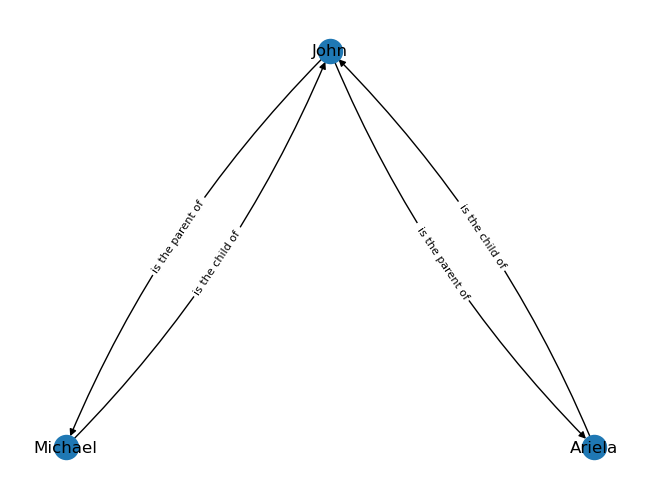

Michael 1 set() {'John'}
Ariela 1 set() {'John'}
John 0 {'Ariela', 'Michael'} set()


In [24]:
testgraph = nx.MultiDiGraph()
testgraph.add_nodes_from(people)
for person in people:
    testgraph.add_edges_from(person.getAllRels())
edge_labels = nx.get_edge_attributes(testgraph, "Rel")
pos = nx.planar_layout(testgraph, 3)
nx.draw(testgraph, pos, labels={person:person.getProp('Name') for person in people}, connectionstyle='arc3, rad = 0.1')
nx.draw_networkx_edge_labels(testgraph, pos=pos, edge_labels=edge_labels, connectionstyle='arc3, rad = 0.1', font_size=8)
plt.show()
for person in people:
    print(person.getProp('Name'), person.getProp('Generation'), person.getRel(parent_of)[1], person.getRel(child_of)[1])

# Automatic generation

In [ ]:
people = drawNode(nodes, 5)
rels = [sibling_of, child_of, parent_of, spouse_of]
for subj in people:
    print(subj.getProp('Name'))
    attempt = 0
    for attempt in range(8):
        rel = np.random.choice(rels, 1)[0]
        print(rel.getName())
        obj = drawNode(people, 1)[0]
        print(obj.getProp('Name'))
        if tryRelation(subj, obj, rel) is True:
            break

Raffaella
is the spouse of
Miriam
Call to checkShare for relation is the spouse of between Raffaella and Miriam
Calle to checkRecip for relation is the spouse of between Raffaella and Miriam
Call to checkShare for relation is the spouse of between Miriam and Raffaella
Call to checkOneHop for relation is the spouse of between Miriam and Raffaella
Reciprocity check failed
is the child of
Miriam
Call to checkShare for relation is the child of between Raffaella and Miriam
Calle to checkRecip for relation is the child of between Raffaella and Miriam
Call to checkShare for relation is the parent of between Miriam and Raffaella
Call to checkOneHop for relation is the parent of between Miriam and Raffaella
> Checking hopped relation is the sibling of
>> Hopped relation is the sibling of not present, continuing on
Reciprocity check failed
is the parent of
Tagora
Call to checkShare for relation is the parent of between Raffaella and Tagora
Calle to checkRecip for relation is the parent of betwee

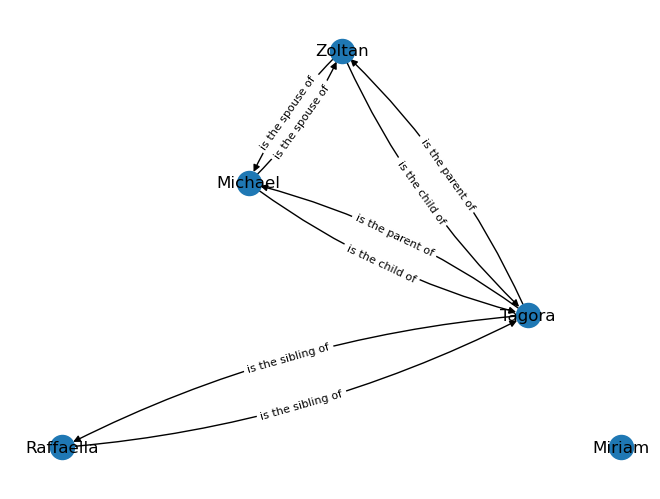

Raffaella 0 set() set()
Miriam 2 set() set()
Tagora 0 {'Michael', 'Zoltan'} set()
Zoltan 1 set() {'Tagora'}
Michael 1 set() {'Tagora'}


In [ ]:
nodes = loadSpec("./testGraph1.yml")
testgraph = nx.MultiDiGraph()
testgraph.add_nodes_from(people)
for person in people:
    testgraph.add_edges_from(person.getAllRels())
edge_labels = nx.get_edge_attributes(testgraph, "Rel")
pos = nx.planar_layout(testgraph, 3)
nx.draw(testgraph, pos, labels={person:person.getProp('Name') for person in people}, connectionstyle='arc3, rad = 0.1')
nx.draw_networkx_edge_labels(testgraph, pos=pos, edge_labels=edge_labels, connectionstyle='arc3, rad = 0.1', font_size=8)
plt.show()
for person in people:
    print(person.getProp('Name'), person.getProp('Generation'), person.getRel(parent_of)[1], person.getRel(child_of)[1])